# Practical 6: RNN sentiment classifier using LSTM

**Idea:** tags are the hidden states, words are the observations.
We learn two things from a tagged corpus:
- **Transition probability** P(tag | previous tag)
- **Emission probability** P(word | tag)

Then Viterbi finds the best tag sequence for a new sentence.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from collections import Counter

# Reproducibility
tf.random.set_seed(42)
np.random.seed(42)

VOCAB_SIZE = 20000   # keep the 20k most frequent words
MAX_LEN = 300        # pad/cut every review to 300 words

In [2]:
# 25,000 train reviews and 25,000 test reviews (already split, labels: 0 = negative, 1 = positive)
(x_train_raw, y_train), (x_test_raw, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print("Train reviews:", len(x_train_raw))
print("Test reviews :", len(x_test_raw))

# Make all reviews the same length
x_train = pad_sequences(x_train_raw, maxlen=MAX_LEN)
x_test = pad_sequences(x_test_raw, maxlen=MAX_LEN)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train reviews: 25000
Test reviews : 25000


In [3]:
model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(VOCAB_SIZE, 128),
    layers.SpatialDropout1D(0.3),
    layers.Bidirectional(layers.LSTM(64, dropout=0.2)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 300, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,667,137 (10.17 MB)

 Trainable params: 2,667,137 (10.17 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - accuracy: 0.7573 - loss: 0.4785 - val_accuracy: 0.8548 - val_loss: 0.3599
Epoch 2/8
176/176 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.9026 - loss: 0.2512 - val_accuracy: 0.8908 - val_loss: 0.3062
Epoch 3/8
176/176 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.9320 - loss: 0.1864 - val_accuracy: 0.8852 - val_loss: 0.3478
Epoch 4/8
176/176 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - accuracy: 0.9396 - loss: 0.1676 - val_accuracy: 0.8112 - val_loss: 0.4039


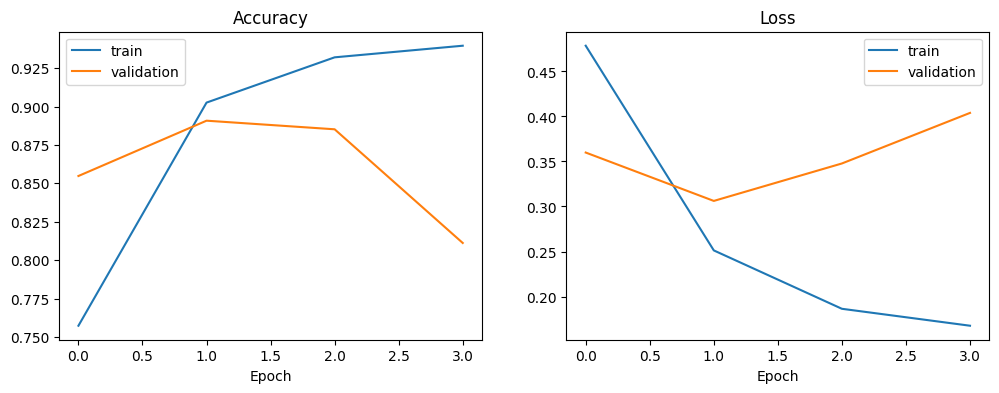

In [4]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)

history = model.fit(
    x_train, y_train,
    epochs=8,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1,
)

# Training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.show()

Test Accuracy: 0.88
Test F1-score: 0.8826

              precision    recall  f1-score   support

    Negative       0.90      0.86      0.88     12500
    Positive       0.86      0.90      0.88     12500

    accuracy                           0.88     25000
   macro avg       0.88      0.88      0.88     25000
weighted avg       0.88      0.88      0.88     25000



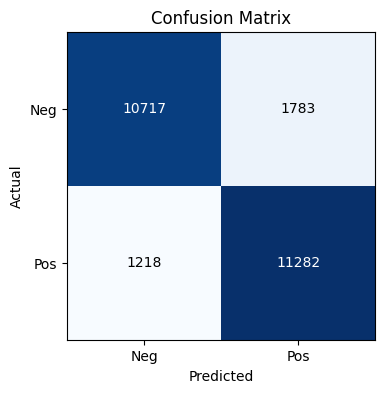

In [5]:
y_prob = model.predict(x_test, batch_size=256, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Test F1-score:", round(f1_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 4))
plt.imshow(cm, cmap="Blues")
plt.xticks([0, 1], ["Neg", "Pos"]); plt.yticks([0, 1], ["Neg", "Pos"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.show()

In [6]:
# Turn word indices back into readable text
word_index = imdb.get_word_index()
index_to_word = {v + 3: k for k, v in word_index.items()}
index_to_word.update({0: "<pad>", 1: "<start>", 2: "<unk>", 3: "<unused>"})

def decode(seq):
    return " ".join(index_to_word.get(i, "?") for i in seq if i > 3)

wrong = np.where(y_pred != y_test)[0]
false_pos = np.where((y_pred == 1) & (y_test == 0))[0]   # said positive, actually negative
false_neg = np.where((y_pred == 0) & (y_test == 1))[0]   # said negative, actually positive

print(f"Total errors   : {len(wrong)} out of {len(y_test)}")
print(f"False positives: {len(false_pos)}")
print(f"False negatives: {len(false_neg)}")

# 1) Are errors linked to review length?
lengths = np.array([len(r) for r in x_test_raw])
print("\nAverage length (all reviews)  :", int(lengths.mean()), "words")
print("Average length (wrong reviews):", int(lengths[wrong].mean()), "words")
print("Error rate for short reviews (<100 words)  :",
      round(np.mean(y_pred[lengths < 100] != y_test[lengths < 100]), 3))
print("Error rate for long reviews (>400 words)   :",
      round(np.mean(y_pred[lengths > 400] != y_test[lengths > 400]), 3))

# 2) Most confident mistakes
confidence = np.abs(y_prob - 0.5)
worst = wrong[np.argsort(-confidence[wrong])][:5]
print("\n===== 5 most confident wrong predictions =====")
for idx in worst:
    actual = "Positive" if y_test[idx] == 1 else "Negative"
    pred = "Positive" if y_pred[idx] == 1 else "Negative"
    print(f"\nActual: {actual} | Predicted: {pred} | P(positive) = {y_prob[idx]:.3f}")
    print(decode(x_test_raw[idx])[:500], "...")

# 3) Words that appear more often in wrong reviews than in all reviews
stop = {"the", "a", "and", "of", "to", "is", "it", "in", "i", "this", "that", "was",
        "as", "for", "with", "but", "on", "movie", "film", "br", "s", "t", "one"}
def word_freq(indices):
    c = Counter()
    for i in indices:
        c.update(w for w in decode(x_test_raw[i]).split() if w not in stop)
    return c

wrong_words = word_freq(wrong)
print("\nMost common words in misclassified reviews:")
print([w for w, _ in wrong_words.most_common(15)])

# 4) Mixed-sentiment signal: words like 'but', 'however', 'although'
mixed_words = {"but", "however", "although", "though", "despite"}
def has_mixed(i):
    return any(w in mixed_words for w in decode(x_test_raw[i]).split())
mixed_error = np.mean([has_mixed(i) for i in wrong[:2000]])
mixed_all = np.mean([has_mixed(i) for i in range(2000)])
print(f"\nReviews with 'but/however/although' -> in errors: {mixed_error:.2%}, overall: {mixed_all:.2%}")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total errors   : 3001 out of 25000
False positives: 1783
False negatives: 1218

Average length (all reviews)  : 230 words
Average length (wrong reviews): 245 words
Error rate for short reviews (<100 words)  : 0.116
Error rate for long reviews (>400 words)   : 0.144

===== 5 most confident wrong predictions =====

Actual: Negative | Predicted: Positive | P(positive) = 1.000
i went to see this 3 nights ago here in ireland it was the world premiere of it in the tiny cinema in the arts centre as part of the film festival br br i found strange fruit to be an excellent movie it is a bit rough around the edges but for a low budget movie that is to be expected in general the acting particularly from the main lead kent is wonderful the cinematography and direction excellent and the script hugely entertaining and thought provoking with some nice set ups and witty dialogue b ...

Actual: Negative | Predicted: Positive | P(positive) = 1.000
this fil

In [7]:
def predict_review(text):
    words = text.lower().replace(",", "").replace(".", "").replace("!", "").split()
    seq = [word_index.get(w, -3) + 3 for w in words]
    seq = [i if i < VOCAB_SIZE else 2 for i in seq]
    seq = [1] + seq
    padded = pad_sequences([seq], maxlen=MAX_LEN)
    p = model.predict(padded, verbose=0)[0][0]
    print(f"{'Positive' if p > 0.5 else 'Negative'} ({p:.2f}) -> {text}")

predict_review("This movie was absolutely wonderful, I loved the acting and the story")
predict_review("Terrible film, boring plot and awful acting. Waste of time")
predict_review("The visuals were good but the story was dull and too long")

Positive (0.85) -> This movie was absolutely wonderful, I loved the acting and the story
Negative (0.00) -> Terrible film, boring plot and awful acting. Waste of time
Negative (0.24) -> The visuals were good but the story was dull and too long
